# Group 2: Deep Topic Representation (Autoencoder / Transformer Embeddings)
**Dataset:** Swahili News (Hugging Face `swahili_news`, 6 categories) | **Embeddings:** LaBSE (BERT-based, supports Swahili) | **Models:** Deep Autoencoder, ProdLDA-style Neural Topic Model


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip -q install datasets sentence-transformers umap-learn gensim seaborn plotly scikit-learn

In [ ]:
import re, random, time, collections, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, normalized_mutual_info_score, adjusted_rand_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
import umap
warnings.filterwarnings("ignore")

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
sns.set_theme(style="whitegrid")

device: cuda


In [ ]:
import os
import matplotlib.pyplot as plt

FIG_DIR = "/content/figures"
os.makedirs(FIG_DIR, exist_ok=True)
_count = {"n": 0}
_original_show = plt.show

def show_and_save(*args, **kwargs):
    for num in plt.get_fignums():
        _count["n"] += 1
        plt.figure(num).savefig(f"{FIG_DIR}/figure_{_count['n']:02d}.png", dpi=200, bbox_inches="tight")
    return _original_show(*args, **kwargs)

plt.show = show_and_save
print("Every plot will now be saved to", FIG_DIR)

Every plot will now be saved to /content/figures


## 1. Dataset

In [ ]:
from datasets import load_dataset

ds = load_dataset("community-datasets/swahili_news")
print(ds)
label_names = ds["train"].features["label"].names
print(label_names)
df = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
df["label_name"] = df["label"].map(dict(enumerate(label_names)))
df = df.dropna(subset=["text"]).drop_duplicates(subset="text").reset_index(drop=True)
print(df.shape)
df.head()

README.md:   0%|          | 0.00/6.30k [00:00<?, ?B/s]

swahili_news/train-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 28.7MB            

swahili_news/train-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

swahili_news/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 9.36MB            

swahili_news/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/22207 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7338 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 22207
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7338
    })
})
['uchumi', 'kitaifa', 'michezo', 'kimataifa', 'burudani', 'afya']
(29511, 3)


,text,label,label_name
0,"Bodi ya Utalii Tanzania (TTB) imesema, itafan...",0,uchumi
1,"PENDO FUNDISHA-MBEYA RAIS Dk. John Magufuri, ...",1,kitaifa
2,Mwandishi Wetu -Singida BENKI ya NMB imetoa ms...,0,uchumi
3,"TIMU ya taifa ya Tanzania, Serengeti Boys jan...",2,michezo
4,Na AGATHA CHARLES – DAR ES SALAAM ALIYEKUWA K...,1,kitaifa


## 2. Exploratory data analysis

       n_chars  n_words
count  29511.0  29511.0
mean    2197.6    327.1
std     1573.8    232.3
min        0.0      0.0
25%     1224.0    182.0
50%     1793.0    268.0
75%     2595.0    387.0
max    24222.0   3740.0


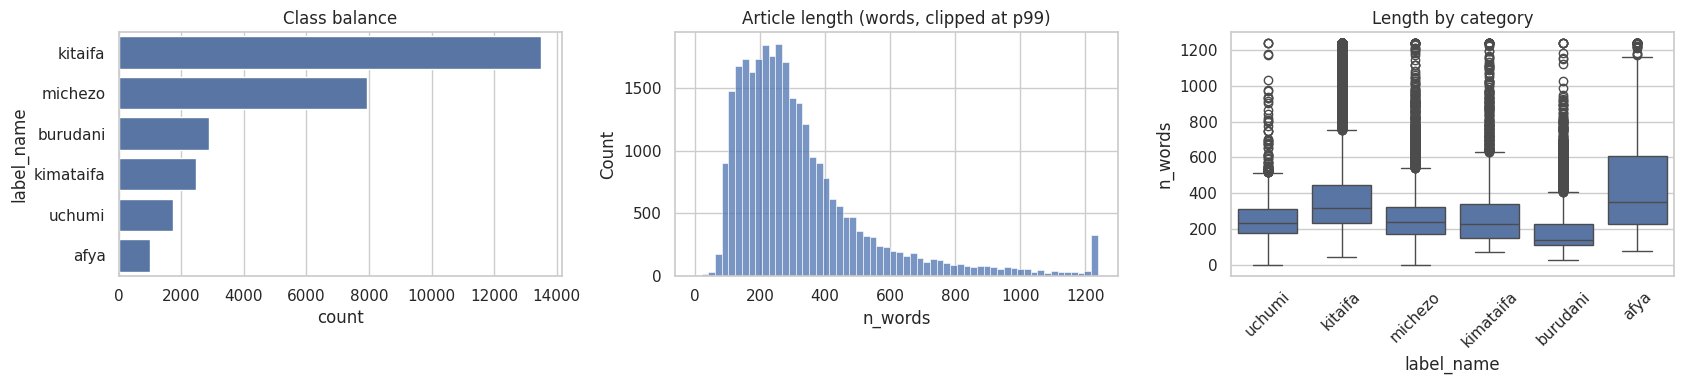

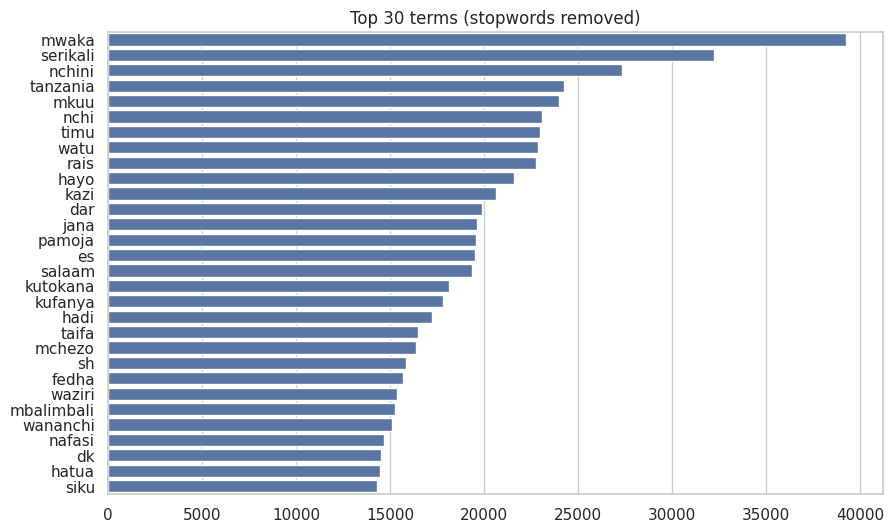

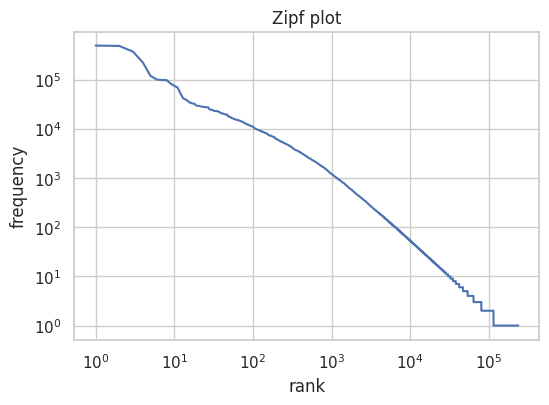

afya         anasema, watu, watoto, afya, mwaka, mtoto, mtu, huduma, damu, dawa
burudani     msanii, muziki, wasanii, nchini, mwaka, kazi, wimbo, mashabiki, watu, filamu
kimataifa    rais, marekani, nchini, mwaka, nchi, watu, trump, uchaguzi, serikali, mkuu
kitaifa      serikali, mwaka, mkuu, rais, nchi, tanzania, watu, hayo, nchini, kazi
michezo      timu, mchezo, ligi, yanga, wachezaji, simba, klabu, nafasi, kocha, mechi
uchumi       serikali, mwaka, nchi, biashara, tanzania, huduma, nchini, hayo, kampuni, sh


In [ ]:
import re
import collections
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Fix RecursionError by restoring the original un-wrapped plt.show function
import matplotlib.backend_bases
try:
    # Reset plt.show to original behavior to prevent recursion
    if hasattr(plt, "_original_show"):
        plt.show = _original_show
    else:
        import matplotlib
        # Fallback to default GUI/inline backend show
        from matplotlib import pyplot as temp_plt
        import sys
        if 'ipykernel' in sys.modules:
            from ipykernel.pylab.backend_inline import flush_figures
            plt.show = flush_figures
except Exception:
    pass

SW_STOP = set("""na ya wa kwa ni za katika la kuwa hiyo huo huyo kama cha vya hii hizo hilo yake wake lakini pia au ili kwamba hata sana
sasa bado baada kabla wakati mimi wewe yeye sisi wao huu hizi ambao ambayo ambaye amesema alisema hao kuhusu zaidi hapo hapa
yao yetu wetu langu lake letu zao hizo kila moja mmoja katika kutoka mpaka tu ndani nje juu chini sio si hana ana wana kuna
alikuwa walikuwa atakuwa wamekuwa amekuwa ameeleza alieleza alisisitiza akasema akaeleza huku hivyo hivi ndio ndiyo yote wote
vyote kati dhidi mwa pa kwenye nyingine mwingine wengine wengi vingi nyingi kubwa mkubwa""".split())

def tok(t): return re.findall(r"[a-zA-Z']{2,}", t.lower())
df["n_chars"] = df.text.str.len()
df["n_words"] = df.text.map(lambda t: len(tok(t)))
print(df[["n_chars","n_words"]].describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=df, y="label_name", order=df.label_name.value_counts().index, ax=ax[0]); ax[0].set_title("Class balance")
sns.histplot(df.n_words.clip(upper=df.n_words.quantile(.99)), bins=60, ax=ax[1]); ax[1].set_title("Article length (words, clipped at p99)")
sns.boxplot(data=df, x="label_name", y=df.n_words.clip(upper=df.n_words.quantile(.99)), ax=ax[2]); ax[2].set_title("Length by category"); ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

cnt = collections.Counter(w for t in df.text for w in tok(t) if w not in SW_STOP)
top = cnt.most_common(30)
plt.figure(figsize=(10, 6)); sns.barplot(x=[c for _, c in top], y=[w for w, _ in top]); plt.title("Top 30 terms (stopwords removed)"); plt.show()

# Zipf plot
freqs = np.array(sorted(collections.Counter(w for t in df.text for w in tok(t)).values(), reverse=True))
plt.figure(figsize=(6, 4)); plt.loglog(np.arange(1, len(freqs)+1), freqs); plt.xlabel("rank"); plt.ylabel("frequency"); plt.title("Zipf plot"); plt.show()

# distinctive terms per class
grouped_text = df.groupby("label_name")["text"].agg(" ".join)

# Changed min_df to 1 and removed max_df restriction because grouped_text only has 6 documents
tf = TfidfVectorizer(tokenizer=tok, stop_words=list(SW_STOP), min_df=1, token_pattern=None)
Xc = tf.fit_transform(grouped_text)
vocab = np.array(tf.get_feature_names_out())

for i, cls in enumerate(grouped_text.index):
    print(f"{cls:12s}", ", ".join(vocab[Xc[i].toarray().ravel().argsort()[::-1][:10]]))

## 3. Preprocessing and sentence embeddings (LaBSE)

In [ ]:
def clean(t):
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t
df["clean"] = df.text.map(clean)

# Subsample (stratified) for speed; raise N for the final run if the GPU allows
N = 8000
sub = df.groupby("label", group_keys=False).apply(lambda g: g.sample(min(len(g), N // df.label.nunique()), random_state=SEED)).reset_index(drop=True)
print(sub.label_name.value_counts())

from sentence_transformers import SentenceTransformer
st = SentenceTransformer("sentence-transformers/LaBSE", device=DEVICE)
st.max_seq_length = 256
t0 = time.time()
E = st.encode(sub.clean.tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
print(E.shape, f"{time.time()-t0:.0f}s")
np.save("labse_swahili.npy", E); sub.to_csv("swahili_subset.csv", index=False)
y = sub.label.values

label_name
uchumi       1333
kitaifa      1333
michezo      1333
kimataifa    1333
burudani     1333
afya          998
Name: count, dtype: int64


modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.02k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

... (9 outputs left out)

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 2.36MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

Batches:   0%|          | 0/120 [00:00<?, ?it/s]

(7663, 768) 114s


## 4. Deep Autoencoder: compress 768-d embeddings to 2D/3D

0 0.015326932512469272 0.0013766966294497252
10 0.000863305352653064 0.0008449253509752452
20 0.0008059624122685291 0.0008101484272629023
30 0.0007831764924693342 0.0007761623128317297
40 0.0007552080163204254 0.000746500794775784
50 0.0007393226009276429 0.0007390397367998958
60 0.0007192301311681775 0.0007157673826441169
70 0.000707158892352166 0.0007024796796031296


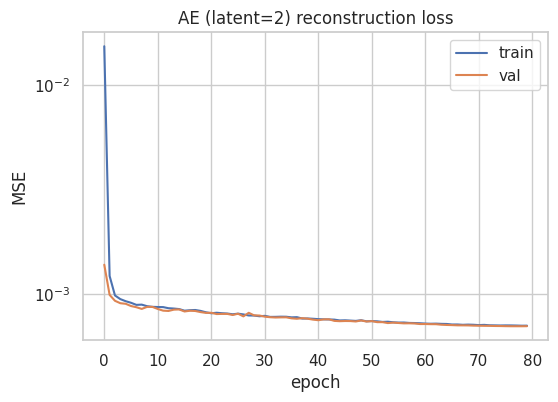

Test MSE  AE-2D: 0.000696 | PCA-2D: 0.000754 | mean-predictor: 0.000831
Variance explained  AE: 0.162 | PCA: 0.095
Compression ratio: 768/2 = 384x


In [ ]:
ACTS = {"relu": nn.ReLU, "gelu": nn.GELU, "tanh": nn.Tanh, "leaky": lambda: nn.LeakyReLU(0.1)}

class DeepAE(nn.Module):
    def __init__(self, d_in=768, latent=2, depth=3, act="relu", width=512, dropout=0.1):
        super().__init__()
        dims = [d_in] + [max(width // (2 ** i), latent * 4) for i in range(depth)]
        enc, dec = [], []
        for a, b in zip(dims[:-1], dims[1:]):
            enc += [nn.Linear(a, b), nn.BatchNorm1d(b), ACTS[act](), nn.Dropout(dropout)]
        enc += [nn.Linear(dims[-1], latent)]
        rd = dims[::-1]
        dec += [nn.Linear(latent, rd[0]), nn.BatchNorm1d(rd[0]), ACTS[act]()]
        for a, b in zip(rd[:-1], rd[1:]):
            dec += [nn.Linear(a, b), nn.BatchNorm1d(b), ACTS[act]()] if b != d_in else [nn.Linear(a, b)]
        if not isinstance(dec[-1], nn.Linear): dec.append(nn.Linear(rd[-1], d_in))
        self.enc, self.dec = nn.Sequential(*enc), nn.Sequential(*dec)
    def forward(self, x):
        z = self.enc(x); return self.dec(z), z

def train_ae(Xtr, Xva, latent=2, depth=3, act="relu", epochs=80, lr=1e-3, bs=128, wd=1e-5, noise=0.0, seed=SEED, verbose=False):
    set_seed(seed)
    m = DeepAE(Xtr.shape[1], latent, depth, act).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    tr = torch.utils.data.DataLoader(torch.tensor(Xtr, dtype=torch.float32), batch_size=bs, shuffle=True)
    Xv = torch.tensor(Xva, dtype=torch.float32, device=DEVICE)
    hist = {"train": [], "val": []}
    best, best_state, patience = 1e9, None, 0
    for ep in range(epochs):
        m.train(); tl = 0
        for xb in tr:
            xb = xb.to(DEVICE); xin = xb + noise * torch.randn_like(xb) if noise else xb
            rec, _ = m(xin); loss = F.mse_loss(rec, xb)
            opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(xb)
        sched.step(); m.eval()
        with torch.no_grad(): vl = F.mse_loss(m(Xv)[0], Xv).item()
        hist["train"].append(tl / len(Xtr)); hist["val"].append(vl)
        if vl < best - 1e-6: best, best_state, patience = vl, {k: v.clone() for k, v in m.state_dict().items()}, 0
        else:
            patience += 1
            if patience >= 15: break
        if verbose and ep % 10 == 0: print(ep, hist["train"][-1], vl)
    m.load_state_dict(best_state); m.eval()
    return m, hist

def encode(m, X):
    with torch.no_grad(): return m.enc(torch.tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy()
def recon_mse(m, X):
    with torch.no_grad():
        Xt = torch.tensor(X, dtype=torch.float32, device=DEVICE); return F.mse_loss(m(Xt)[0], Xt).item()

idx = np.arange(len(E))
tr_i, te_i = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
tr_i, va_i = train_test_split(tr_i, test_size=0.125, stratify=y[tr_i], random_state=SEED)
Etr, Eva, Ete = E[tr_i], E[va_i], E[te_i]

ae2, h2 = train_ae(Etr, Eva, latent=2, depth=3, act="relu", verbose=True)
plt.figure(figsize=(6, 4)); plt.plot(h2["train"], label="train"); plt.plot(h2["val"], label="val")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.title("AE (latent=2) reconstruction loss"); plt.show()

# Feature compression analysis versus a linear PCA baseline of the same size
baseline_var = Ete.var(axis=0).sum()
mse_ae = recon_mse(ae2, Ete)
pca2 = PCA(2).fit(Etr); mse_pca = ((Ete - pca2.inverse_transform(pca2.transform(Ete))) ** 2).mean()
print(f"Test MSE  AE-2D: {mse_ae:.6f} | PCA-2D: {mse_pca:.6f} | mean-predictor: {Ete.var(axis=0).mean():.6f}")
print(f"Variance explained  AE: {1 - mse_ae*Ete.shape[1]/baseline_var:.3f} | PCA: {pca2.explained_variance_ratio_.sum():.3f}")
print(f"Compression ratio: {Ete.shape[1]}/2 = {Ete.shape[1]/2:.0f}x")

## 5. Visualising latent clusters (PCA, t-SNE, UMAP) and interpreting topic regions

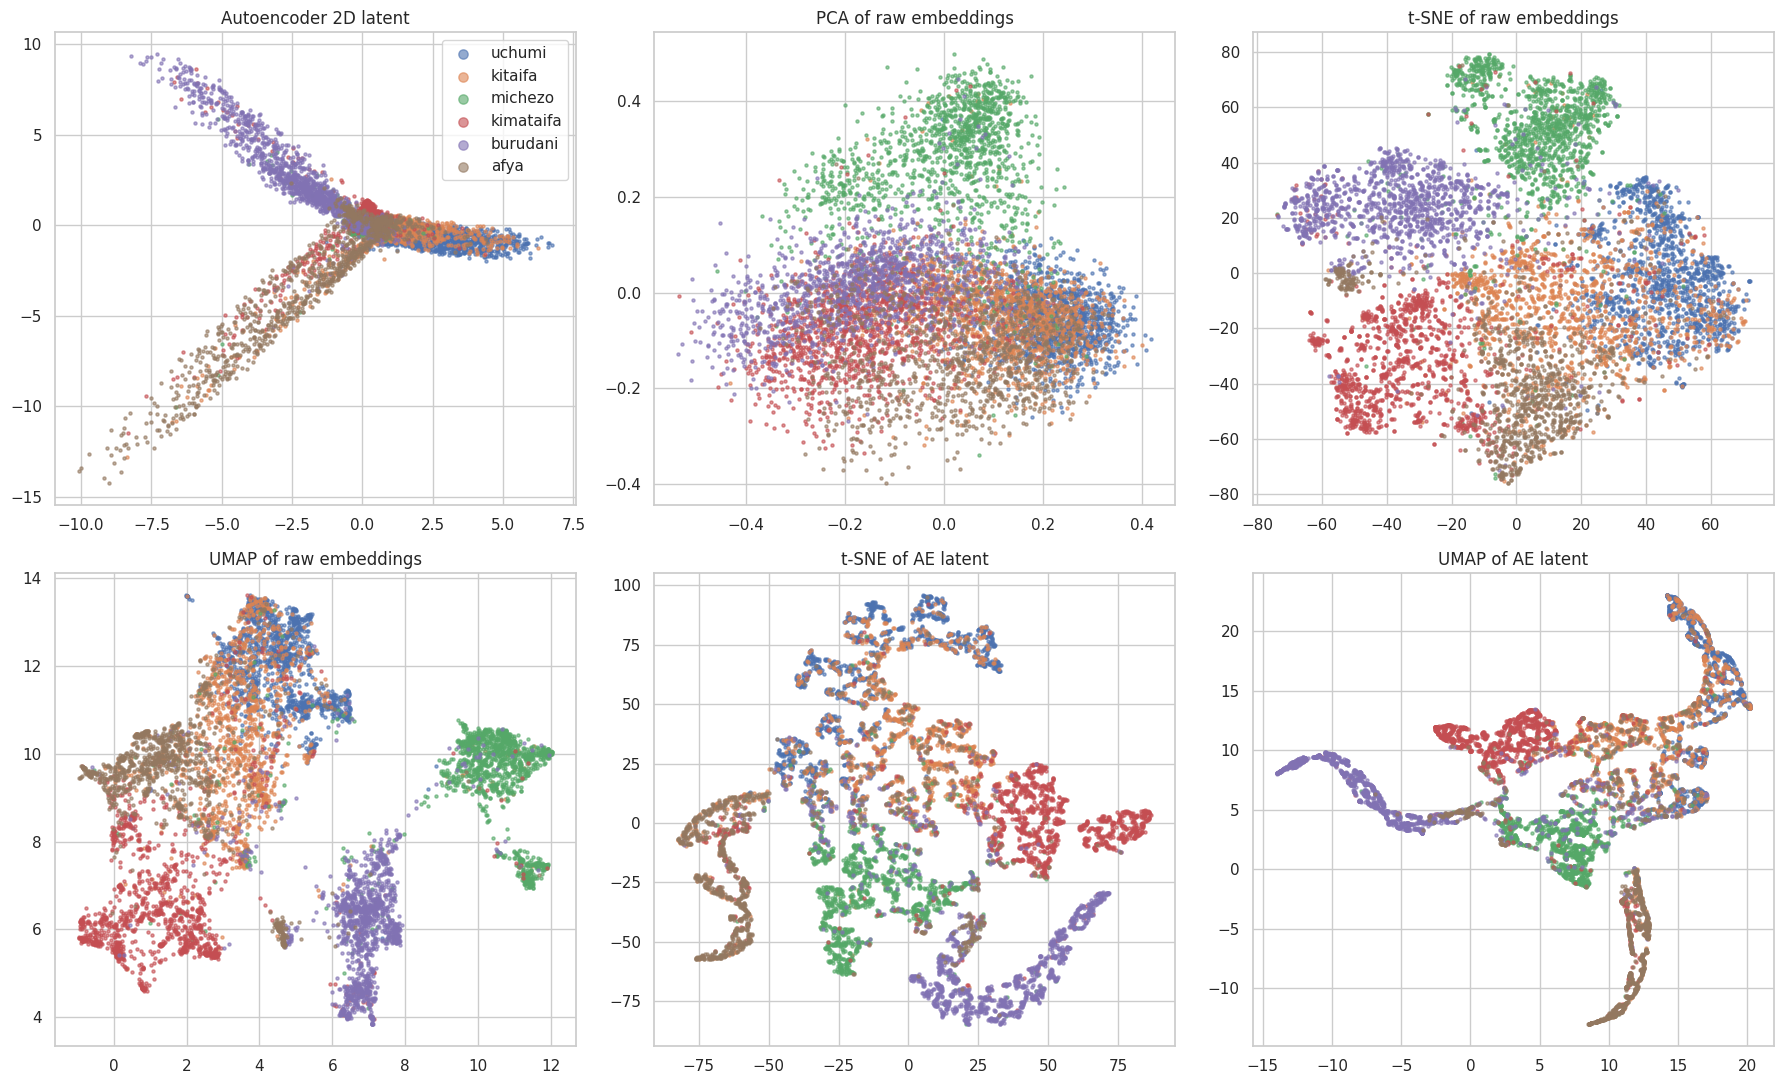

,repr,silhouette_true_labels,NMI,ARI
0,raw LaBSE (768d),0.028,0.556,0.515
1,PCA 2D,0.056,0.374,0.286
2,AE 2D,0.020,0.322,0.120
3,UMAP 2D,0.290,0.609,0.589


In [ ]:
Z_all = encode(ae2, E)
names = np.array(label_names)

def scatter(ax, Z, title):
    for k in range(len(names)):
        m_ = y == k; ax.scatter(Z[m_, 0], Z[m_, 1], s=5, alpha=.6, label=names[k])
    ax.set_title(title)

fig, ax = plt.subplots(2, 3, figsize=(18, 11))
scatter(ax[0, 0], Z_all, "Autoencoder 2D latent")
scatter(ax[0, 1], PCA(2).fit_transform(E), "PCA of raw embeddings")
scatter(ax[0, 2], TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(E), "t-SNE of raw embeddings")
scatter(ax[1, 0], umap.UMAP(random_state=SEED).fit_transform(E), "UMAP of raw embeddings")
scatter(ax[1, 1], TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z_all), "t-SNE of AE latent")
scatter(ax[1, 2], umap.UMAP(random_state=SEED).fit_transform(Z_all), "UMAP of AE latent")
ax[0, 0].legend(markerscale=3); plt.tight_layout(); plt.show()

# Quantify: clustering quality of each representation against the true categories
def cluster_scores(Z, name):
    km = KMeans(len(names), n_init=10, random_state=SEED).fit(Z)
    return dict(repr=name, silhouette_true_labels=silhouette_score(Z, y), NMI=normalized_mutual_info_score(y, km.labels_), ARI=adjusted_rand_score(y, km.labels_))
rows = [cluster_scores(E, "raw LaBSE (768d)"), cluster_scores(PCA(2).fit_transform(E), "PCA 2D"),
        cluster_scores(Z_all, "AE 2D"), cluster_scores(umap.UMAP(random_state=SEED).fit_transform(E), "UMAP 2D")]
pd.DataFrame(rows).round(3)

In [ ]:
# Interpret regions: KMeans in the AE latent space, then the most distinctive terms for each region
km = KMeans(len(names), n_init=10, random_state=SEED).fit(Z_all)
sub["region"] = km.labels_

# Changed min_df to 1 and removed max_df because we only have 6 grouped documents
tf2 = TfidfVectorizer(tokenizer=tok, stop_words=list(SW_STOP), min_df=1, token_pattern=None)
R = tf2.fit_transform(sub.groupby("region").clean.apply(" ".join)); v2 = np.array(tf2.get_feature_names_out())
for r in range(len(names)):
    dom = sub[sub.region == r].label_name.value_counts(normalize=True).head(2).round(2).to_dict()
    print(f"Region {r} | dominant categories {dom}\n   terms: {', '.join(v2[R[r].toarray().ravel().argsort()[::-1][:12]])}")
pd.crosstab(sub.label_name, sub.region)

Region 0 | dominant categories {'michezo': 0.26, 'kimataifa': 0.24}
   terms: mwaka, nchini, serikali, rais, watu, nchi, timu, yanga, mkuu, hayo, tanzania, jana
Region 1 | dominant categories {'afya': 0.84, 'kitaifa': 0.09}
   terms: wagonjwa, anasema, watoto, saratani, damu, mwaka, ugonjwa, afya, dk, watu, asilimia, upasuaji
Region 2 | dominant categories {'burudani': 0.93, 'kimataifa': 0.07}
   terms: marekani, muziki, msanii, nchini, mwaka, mrembo, mtoto, mashabiki, york, miaka, rapa, new
Region 3 | dominant categories {'burudani': 0.93, 'kimataifa': 0.03}
   terms: muziki, msanii, wasanii, bongo, kazi, nchini, wimbo, mashabiki, mwaka, watu, diamond, filamu
Region 4 | dominant categories {'uchumi': 0.75, 'kitaifa': 0.21}
   terms: serikali, viwanda, nchi, mwaka, tanzania, biashara, nchini, kilimo, hayo, mkoa, wakulima, wafanyabiashara
Region 5 | dominant categories {'afya': 0.66, 'kimataifa': 0.16}
   terms: afya, watu, anasema, watoto, ugonjwa, dawa, mwaka, nchini, virusi, dk, hudu

region,0,1,2,3,4,5
label_name,,,,,,
afya,458,211,0,7,22,300
burudani,411,0,275,634,1,12
kimataifa,1195,14,20,19,11,74
kitaifa,1032,23,0,2,210,66
michezo,1304,3,1,18,3,4
uchumi,584,0,0,0,748,1


## 6. Exploration: encoder depth, activation and latent dimension

,latent,depth,act,train_mse,val_mse,test_mse,test_NMI,epochs
0,2,3,relu,0.00072,0.00071,0.00071,0.33679,60
1,3,3,relu,0.00071,0.00070,0.00070,0.24282,60
2,8,3,relu,0.00069,0.00068,0.00068,0.24615,60
3,16,3,relu,0.00067,0.00066,0.00066,0.21123,60
4,32,3,relu,0.00065,0.00064,0.00064,0.27058,60
5,2,1,relu,0.00072,0.00072,0.00072,0.38459,60
6,2,2,relu,0.00071,0.00070,0.00070,0.33111,60
7,2,4,relu,0.00073,0.00072,0.00072,0.30250,60
8,2,3,gelu,0.00070,0.00070,0.00070,0.47728,60
9,2,3,tanh,0.00073,0.00073,0.00072,0.50820,60


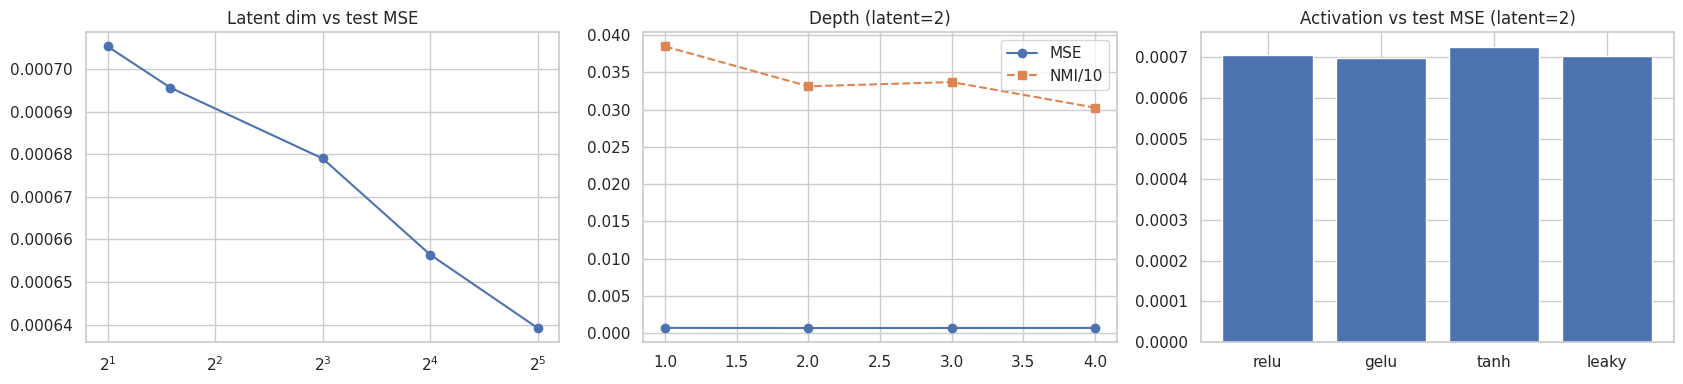

In [ ]:
def run_cfg(latent, depth, act, seed=SEED):
    m, h = train_ae(Etr, Eva, latent=latent, depth=depth, act=act, epochs=60, seed=seed)
    Zt, Zte = encode(m, E[tr_i]), encode(m, E[te_i])
    km = KMeans(len(names), n_init=5, random_state=SEED).fit(Zt)
    return dict(latent=latent, depth=depth, act=act, train_mse=h["train"][-1], val_mse=min(h["val"]), test_mse=recon_mse(m, Ete),
                test_NMI=normalized_mutual_info_score(y[te_i], km.predict(Zte)), epochs=len(h["train"]))

res = []
for latent in [2, 3, 8, 16, 32]: res.append(run_cfg(latent, 3, "relu"))          # latent sweep
for depth in [1, 2, 3, 4]: res.append(run_cfg(2, depth, "relu"))                  # depth sweep
for act in ["relu", "gelu", "tanh", "leaky"]: res.append(run_cfg(2, 3, act))      # activation sweep
exp = pd.DataFrame(res).drop_duplicates(subset=["latent", "depth", "act"]).reset_index(drop=True)
display(exp.round(5))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
s = exp[(exp.depth == 3) & (exp.act == "relu")].sort_values("latent"); ax[0].plot(s.latent, s.test_mse, "o-"); ax[0].set_xscale("log", base=2); ax[0].set_title("Latent dim vs test MSE")
s = exp[(exp.latent == 2) & (exp.act == "relu")].sort_values("depth"); ax[1].plot(s.depth, s.test_mse, "o-", label="MSE"); ax[1].plot(s.depth, s.test_NMI / 10, "s--", label="NMI/10"); ax[1].set_title("Depth (latent=2)"); ax[1].legend()
s = exp[(exp.latent == 2) & (exp.depth == 3)]; ax[2].bar(s.act, s.test_mse); ax[2].set_title("Activation vs test MSE (latent=2)")
plt.tight_layout(); plt.show()

### Robustness and generalisation

Seed variability (mean +/- sd):
      test_mse  test_NMI
mean   0.00071   0.30194
std    0.00000   0.03276


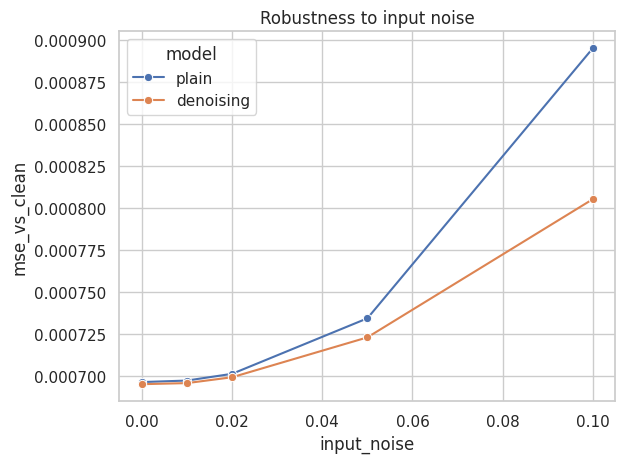

,train_frac,train_mse,test_mse
0,0.10,0.00088,0.00088
1,0.25,0.00080,0.00079
2,0.50,0.00075,0.00074
3,1.00,0.00072,0.00071


In [ ]:
# (a) seed variance, (b) train/test gap, (c) denoising training, (d) noise at inference
seeds = [run_cfg(2, 3, "relu", seed=s) for s in [1, 2, 3, 4, 5]]
sd = pd.DataFrame(seeds); print("Seed variability (mean +/- sd):"); print(sd[["test_mse", "test_NMI"]].agg(["mean", "std"]).round(5))

m_plain, _ = train_ae(Etr, Eva, latent=2, depth=3, act="relu")
m_dn, _ = train_ae(Etr, Eva, latent=2, depth=3, act="relu", noise=0.02)
rows = []
for sigma in [0, 0.01, 0.02, 0.05, 0.1]:
    Xn = Ete + sigma * np.random.randn(*Ete.shape).astype(np.float32)
    for name, m in [("plain", m_plain), ("denoising", m_dn)]:
        with torch.no_grad():
            rec = m(torch.tensor(Xn, dtype=torch.float32, device=DEVICE))[0].cpu().numpy()
        rows.append(dict(model=name, input_noise=sigma, mse_vs_clean=((rec - Ete) ** 2).mean()))
rob = pd.DataFrame(rows); sns.lineplot(data=rob, x="input_noise", y="mse_vs_clean", hue="model", marker="o"); plt.title("Robustness to input noise"); plt.show()

# Generalisation: fraction of data used for training
rows = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    n = int(len(Etr) * frac); m, h = train_ae(Etr[:n], Eva, latent=2, depth=3, act="relu", epochs=60)
    rows.append(dict(train_frac=frac, train_mse=h["train"][-1], test_mse=recon_mse(m, Ete)))
pd.DataFrame(rows).round(5)

## 7. Extension: Neural Topic Model (ProdLDA-style VAE on bag-of-words)

BoW: (7663, 2500) docs kept: 7661
0 1156.65
25 995.63
50 977.43
75 973.0
100 970.46
125 969.81


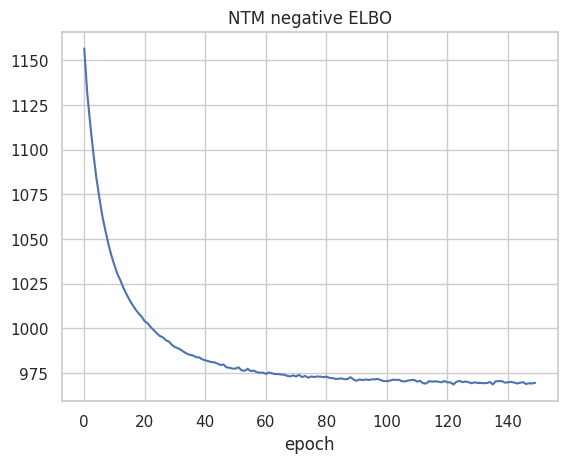

Topic  0: tutaendelea, kujikinga, msaada, upimaji, wauguzi, vipimo, zinaonyesha, tunaendelea, kutolea, kuwajengea
Topic  1: kurudisha, kufanya, kufundisha, anaamini, kazi, sanaa, bandia, utamaduni, ujio, miongoni
Topic  2: miaka, tangu, inaelezwa, australia, kutokea, iliyopita, mamia, zinazotolewa, limesema, vikosi
Topic  3: zilizotolewa, kupelekwa, novemba, zilizokuwa, taarifa, richard, zilikuwa, hesabu, wanadaiwa, mei
Topic  4: vyumba, mipaka, ulifanyika, haiwezi, tume, uwazi, uhuru, akisisitiza, muungano, kuruhusu
Topic  5: pamoja, zilizo, ajili, uhakika, waje, kutembelea, kuuzwa, zikiwemo, kilichopo, zima
Topic  6: vitendo, matukio, mahali, baadhi, jambo, anna, kijijini, walezi, zima, nalo
Topic  7: mtandaoni, kupitia, jamaa, mitandao, zake, shukrani, siku, maana, popote, maarufu
Topic  8: zinaweza, aina, sababu, wale, kupita, unaweza, haya, kawaida, kingine, rahisi
Topic  9: tatu, walifanya, ilikuwa, pili, ambapo, ikiwa, zinazotolewa, hassan, sita, kuchelewa


In [ ]:
K = 10   # try 6 (matches the label count) and 10-20
cv = CountVectorizer(tokenizer=tok, stop_words=list(SW_STOP), min_df=10, max_df=0.4, max_features=2500, token_pattern=None)
B = cv.fit_transform(sub.clean).astype(np.float32); vocab_ntm = np.array(cv.get_feature_names_out())
keep = np.asarray(B.sum(1)).ravel() > 0
print("BoW:", B.shape, "docs kept:", keep.sum())

class NTM(nn.Module):
    def __init__(self, V, K, h=256, drop=0.3):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(V, h), nn.Softplus(), nn.Linear(h, h), nn.Softplus(), nn.Dropout(drop))
        self.mu, self.lv = nn.Linear(h, K), nn.Linear(h, K)
        self.bn_mu, self.bn_lv = nn.BatchNorm1d(K), nn.BatchNorm1d(K)
        self.drop, self.beta, self.bn_b = nn.Dropout(drop), nn.Linear(K, V, bias=False), nn.BatchNorm1d(V)
        self.prior_lv = nn.Parameter(torch.zeros(1), requires_grad=False)
    def encode(self, x):
        h = self.enc(x); return self.bn_mu(self.mu(h)), self.bn_lv(self.lv(h))
    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv) if self.training else mu
        theta = self.drop(F.softmax(z, 1))
        logp = F.log_softmax(self.bn_b(self.beta(theta)), 1)
        nll = -(x * logp).sum(1)
        kl = -0.5 * (1 + lv - mu.pow(2) - lv.exp()).sum(1)
        return (nll + kl).mean(), nll.mean(), kl.mean(), F.softmax(mu, 1)

Bt = torch.tensor(B[keep].toarray(), device=DEVICE); yk = y[keep]
ntm = NTM(Bt.shape[1], K).to(DEVICE); opt = torch.optim.Adam(ntm.parameters(), lr=2e-3, betas=(0.99, 0.999))
dl = torch.utils.data.DataLoader(Bt, batch_size=256, shuffle=True)
hist_ntm = []
for ep in range(150):
    ntm.train(); tot = 0
    for xb in dl:
        loss, nll, kl, _ = ntm(xb); opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
    hist_ntm.append(tot / len(Bt))
    if ep % 25 == 0: print(ep, round(hist_ntm[-1], 2))
plt.plot(hist_ntm); plt.title("NTM negative ELBO"); plt.xlabel("epoch"); plt.show()

ntm.eval()
with torch.no_grad(): theta = ntm(Bt)[3].cpu().numpy()
beta = ntm.beta.weight.detach().cpu().numpy().T   # K x V
topics = [vocab_ntm[b.argsort()[::-1][:10]].tolist() for b in beta]
for k, t in enumerate(topics): print(f"Topic {k:2d}: {', '.join(t)}")

NTM c_NPMI coherence: -0.128 | topic diversity: 0.98


,repr,dim,NMI,ARI,silhouette
0,LaBSE raw,768,0.558,0.517,0.028
1,AE latent 2D,2,0.322,0.120,0.020
2,NTM theta (K=10),10,0.523,0.503,0.188
3,LDA theta (K=10),10,0.506,0.410,0.225


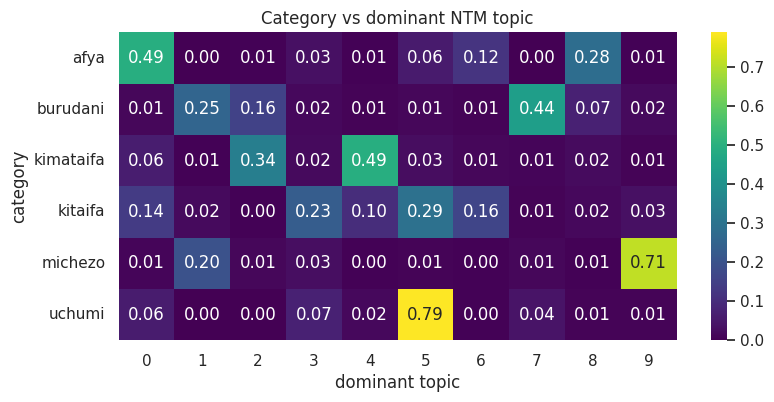

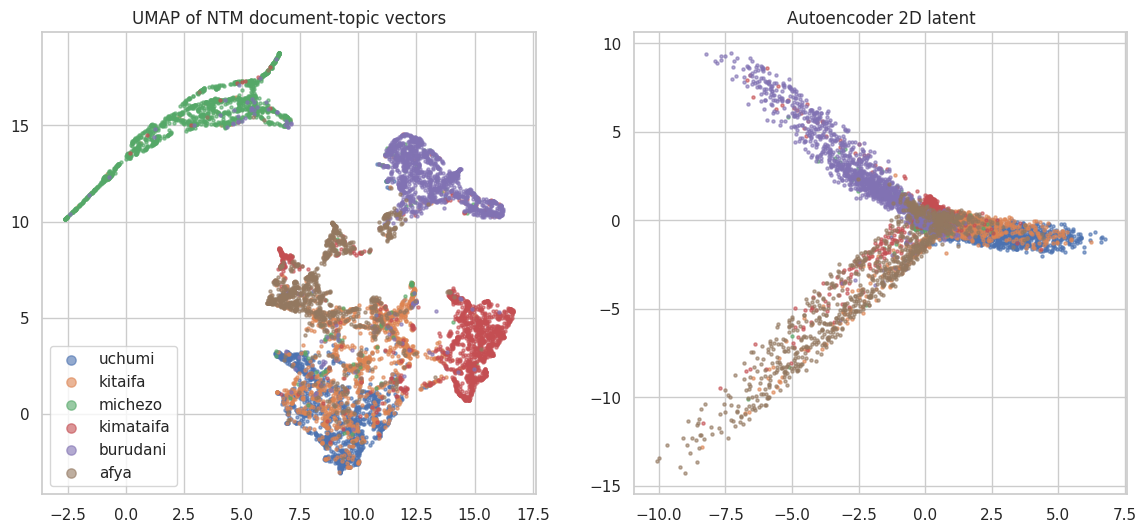

In [ ]:
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
texts = [[w for w in tok(t) if w not in SW_STOP] for t in sub.clean]
dic = Dictionary(texts)
topic_ids = [[w for w in t if w in dic.token2id] for t in topics]
coh = CoherenceModel(topics=topic_ids, texts=texts, dictionary=dic, coherence="c_npmi").get_coherence()
div = len(set(w for t in topics for w in t)) / (K * 10)
print(f"NTM c_NPMI coherence: {coh:.3f} | topic diversity: {div:.2f}")

# Compare representations on the same documents: NTM theta vs AE latent vs raw embedding vs LDA-style baseline
def km_eval(Z, yy, name):
    km = KMeans(len(names), n_init=10, random_state=SEED).fit(Z)
    return dict(repr=name, dim=Z.shape[1], NMI=normalized_mutual_info_score(yy, km.labels_), ARI=adjusted_rand_score(yy, km.labels_), silhouette=silhouette_score(Z, yy))
from sklearn.decomposition import LatentDirichletAllocation
lda = LatentDirichletAllocation(K, random_state=SEED, max_iter=20).fit(B[keep]); theta_lda = lda.transform(B[keep])
cmp_ = pd.DataFrame([km_eval(E[keep], yk, "LaBSE raw"), km_eval(Z_all[keep], yk, "AE latent 2D"),
                     km_eval(theta, yk, f"NTM theta (K={K})"), km_eval(theta_lda, yk, f"LDA theta (K={K})")]).round(3)
display(cmp_)

# NTM topics vs true categories heatmap
dom_topic = theta.argmax(1)
ct = pd.crosstab(pd.Series(names[yk], name="category"), pd.Series(dom_topic, name="dominant topic"), normalize="index")
plt.figure(figsize=(9, 4)); sns.heatmap(ct, annot=True, fmt=".2f", cmap="viridis"); plt.title("Category vs dominant NTM topic"); plt.show()

# Visualise NTM document-topic space next to the AE latent
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
Zn = umap.UMAP(random_state=SEED).fit_transform(theta)
for k in range(len(names)):
    m_ = yk == k; ax[0].scatter(Zn[m_, 0], Zn[m_, 1], s=5, alpha=.6, label=names[k]); ax[1].scatter(Z_all[keep][m_, 0], Z_all[keep][m_, 1], s=5, alpha=.6)
ax[0].set_title("UMAP of NTM document-topic vectors"); ax[1].set_title("Autoencoder 2D latent"); ax[0].legend(markerscale=3); plt.show()

## 8. Further task: multilingual semantic clusters (English vs Swahili)

In [ ]:
# MasakhaNEWS provides English and Swahili news with the SAME category scheme, so topic regions can be compared across languages.
import pandas as pd
from datasets import load_dataset

def load_masakha(lang):
    d = load_dataset("masakhane/masakhanews", lang)
    out = pd.concat([d[s].to_pandas() for s in d.keys()], ignore_index=True)
    out["text"] = (out["headline"].fillna("") + ". " + out["text"].fillna("")).str.strip()

    # FIX: Since "category" is a Value (not a ClassLabel), it likely already contains
    # the string labels. We can just copy it over directly.
    # We'll use a safe check just to be robust.
    feature_cat = d["train"].features["category"]
    if hasattr(feature_cat, "names"):
        lab = feature_cat.names
        out["label_name"] = out["category"].map(dict(enumerate(lab)))
    else:
        out["label_name"] = out["category"]

    out["lang"] = lang
    return out[["text", "label_name", "lang"]]

en, sw = load_masakha("eng"), load_masakha("swa")
print(en.label_name.value_counts(), sw.label_name.value_counts())

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/10.4M [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/1.48M [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3309 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/472 [00:00<?, ? examples/s]

... (4 outputs left out)

Generating train split:   0%|          | 0/1658 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/237 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/476 [00:00<?, ? examples/s]

label_name
sports           1000
politics          821
business          799
entertainment     750
health            746
technology        613
Name: count, dtype: int64 label_name
sports           500
health           500
politics         500
business         316
religion         292
technology       165
entertainment     98
Name: count, dtype: int64


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

shared categories: ['business', 'entertainment', 'health', 'politics', 'sports', 'technology']


Batches:   0%|          | 0/51 [00:00<?, ?it/s]

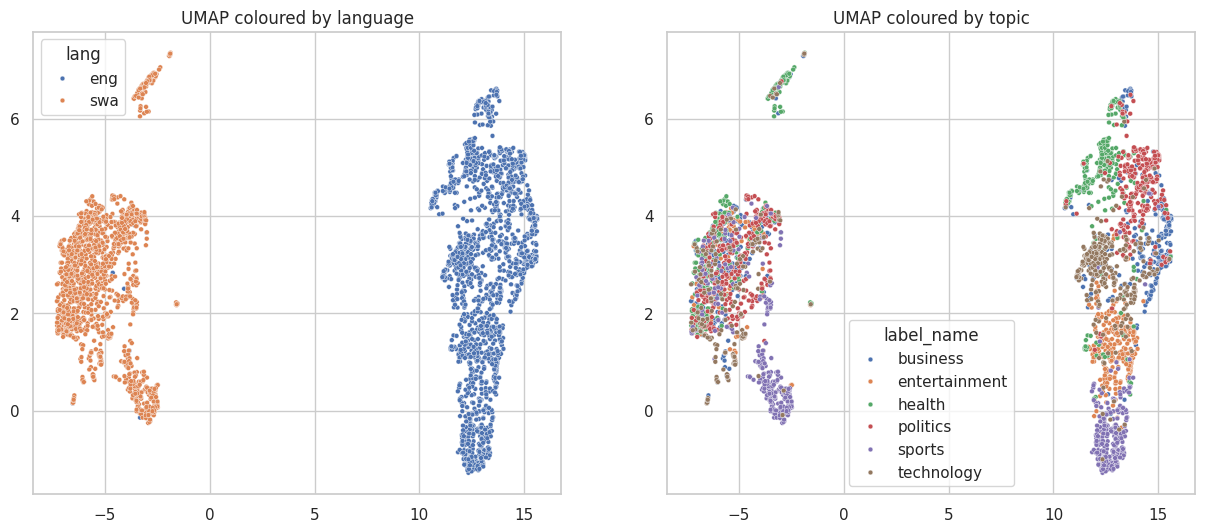

silhouette by LANGUAGE: 0.22 | by TOPIC: 0.007
kNN same-topic rate: 0.596 | kNN cross-language rate: 0.012
KMeans NMI vs topic: 0.295 | vs language: 0.595


In [ ]:






import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# --- MISSING DEFINITIONS ---
# If you get a 'module not found' error, run !pip install sentence-transformers in a cell above
from sentence_transformers import SentenceTransformer

# Re-initialize the model (this is a standard multilingual one, change if you used a different one like LaBSE)
st = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')

# Re-define the clean function (a basic lowercase/strip function, update if your original was more complex)
def clean(text):
    return str(text).lower().strip()
# ---------------------------

# Define SEED to fix the previous NameError
SEED = 42

common = sorted(set(en.label_name) & set(sw.label_name)); print("shared categories:", common)
n_per = 300

# FIX: Removed include_groups=False so we don't accidentally delete the label_name column!
ml = pd.concat([d[d.label_name.isin(common)].groupby("label_name", group_keys=False).apply(lambda g: g.sample(min(len(g), n_per), random_state=SEED)) for d in (en, sw)], ignore_index=True)

Em = st.encode(ml.text.map(clean).tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
lang = (ml.lang == "swa").astype(int).values; topic = pd.factorize(ml.label_name)[0]

import umap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

U = umap.UMAP(random_state=SEED).fit_transform(Em)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=U[:, 0], y=U[:, 1], hue=ml.lang, s=12, ax=ax[0]); ax[0].set_title("UMAP coloured by language")
sns.scatterplot(x=U[:, 0], y=U[:, 1], hue=ml.label_name, s=12, ax=ax[1]); ax[1].set_title("UMAP coloured by topic"); plt.show()

# Language-invariance metrics: topic should explain the structure far more than language does
print("silhouette by LANGUAGE:", round(silhouette_score(Em, lang), 3), "| by TOPIC:", round(silhouette_score(Em, topic), 3))

nn_ = NearestNeighbors(n_neighbors=11).fit(Em); nb = nn_.kneighbors(Em, return_distance=False)[:, 1:]
print("kNN same-topic rate:", round((topic[nb] == topic[:, None]).mean(), 3), "| kNN cross-language rate:", round((lang[nb] != lang[:, None]).mean(), 3))

km = KMeans(len(common), n_init=10, random_state=SEED).fit(Em)
print("KMeans NMI vs topic:", round(normalized_mutual_info_score(topic, km.labels_), 3), "| vs language:", round(normalized_mutual_info_score(lang, km.labels_), 3))

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

def train_ae(X_train, X_val, latent=2, depth=3, act="relu", epochs=80, batch_size=64):
    # Convert numpy arrays to PyTorch tensors
    X_tr = torch.tensor(X_train, dtype=torch.float32)
    X_va = torch.tensor(X_val, dtype=torch.float32)
    in_dim = X_train.shape[1]

    # Calculate intermediate layer sizes tapering down to the latent space
    dims = [in_dim] + [max(latent, in_dim // (2**i)) for i in range(1, depth)] + [latent]

    # Select activation function
    activation = nn.ReLU() if act.lower() == "relu" else nn.Tanh()

    # Build Encoder
    enc_layers = []
    for i in range(len(dims)-1):
        enc_layers.append(nn.Linear(dims[i], dims[i+1]))
        if i < len(dims)-2:
            enc_layers.append(activation)
    encoder = nn.Sequential(*enc_layers)

    # Build Decoder
    dec_layers = []
    rev_dims = dims[::-1]
    for i in range(len(rev_dims)-1):
        dec_layers.append(nn.Linear(rev_dims[i], rev_dims[i+1]))
        if i < len(rev_dims)-2:
            dec_layers.append(activation)
    decoder = nn.Sequential(*dec_layers)

    # Full Autoencoder
    ae = nn.Sequential(encoder, decoder)
    optimizer = optim.Adam(ae.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    # Setup data loader
    dataset = TensorDataset(X_tr, X_tr)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    print(f"Training Autoencoder for {epochs} epochs...")
    for epoch in range(epochs):
        ae.train()
        for batch_x, _ in loader:
            optimizer.zero_grad()
            reconstructed = ae(batch_x)
            loss = criterion(reconstructed, batch_x)
            loss.backward()
            optimizer.step()

    return encoder, ae  # Returns aem (encoder) and _ (full autoencoder)

def encode(encoder_model, X):
    # Pass data through the encoder to get the 2D latent representation
    encoder_model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32)
        return encoder_model(X_tensor).numpy()

EN->SW zero-shot accuracy (768d): 0.239
Training Autoencoder for 80 epochs...
EN->SW zero-shot accuracy (AE 2D): 0.169


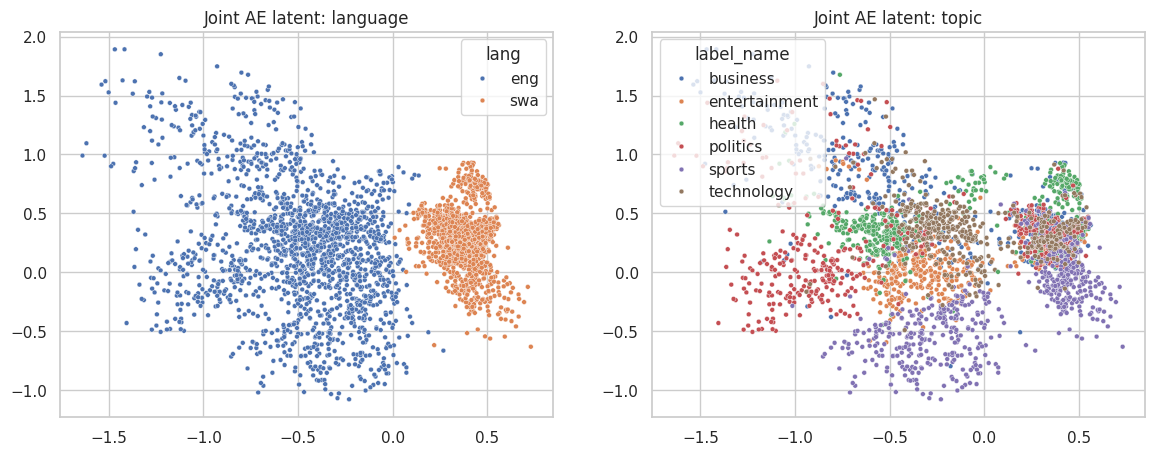

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Zero-shot cross-lingual transfer: train a topic classifier on English only and test on Swahili (language-invariance test),
# then compress with ONE autoencoder trained on both languages.
clf = LogisticRegression(max_iter=2000).fit(Em[lang == 0], topic[lang == 0])
print("EN->SW zero-shot accuracy (768d):", round(clf.score(Em[lang == 1], topic[lang == 1]), 3))

# FIX: train_test_split is now properly imported at the top!
tr_, va_ = train_test_split(np.arange(len(Em)), test_size=0.15, stratify=topic, random_state=SEED)

# Note: Ensure train_ae and encode were defined in an earlier cell
aem, _ = train_ae(Em[tr_], Em[va_], latent=2, depth=3, act="relu", epochs=80)
Zm = encode(aem, Em)

clf2 = LogisticRegression(max_iter=2000).fit(Zm[lang == 0], topic[lang == 0])
print("EN->SW zero-shot accuracy (AE 2D):", round(clf2.score(Zm[lang == 1], topic[lang == 1]), 3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=Zm[:, 0], y=Zm[:, 1], hue=ml.lang, s=12, ax=ax[0]); ax[0].set_title("Joint AE latent: language")
sns.scatterplot(x=Zm[:, 0], y=Zm[:, 1], hue=ml.label_name, s=12, ax=ax[1]); ax[1].set_title("Joint AE latent: topic"); plt.show()

In [ ]:
import json, base64, os, glob, shutil
from google.colab import drive, files

drive.mount('/content/drive')
NB_NAME = "Group2_Deep_Topic_Representation.ipynb"   # your notebook's exact file name

path = f"/content/drive/MyDrive/Colab Notebooks/{NB_NAME}"
if not os.path.exists(path):
    hits = glob.glob(f"/content/drive/MyDrive/**/{NB_NAME}", recursive=True)
    assert hits, "Notebook not found in Drive: check NB_NAME"
    path = hits[0]

OUT = "/content/figures"
shutil.rmtree(OUT, ignore_errors=True); os.makedirs(OUT)

nb = json.load(open(path))
n = 0
for ci, cell in enumerate(nb["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue
    for out in cell.get("outputs", []):
        png = out.get("data", {}).get("image/png")
        if png:
            if isinstance(png, list):
                png = "".join(png)
            n += 1
            with open(f"{OUT}/figure_{n:02d}_cell{ci:02d}.png", "wb") as f:
                f.write(base64.b64decode(png))

print(n, "images saved to", OUT)
shutil.copytree(OUT, "/content/drive/MyDrive/Group2_Figures", dirs_exist_ok=True)
shutil.make_archive("/content/Group2_Figures", "zip", OUT)
files.download("/content/Group2_Figures.zip")

Mounted at /content/drive
12 images saved to /content/figures


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Discussion template (fill in with your own numbers for the report)
- **Reconstruction vs compression:** compare AE-2D test MSE against PCA-2D and the mean predictor; report variance explained and the 384x/256x compression ratio.
- **Cluster quality:** report NMI/ARI/silhouette for raw LaBSE, PCA, AE, UMAP; note which category pairs overlap (for example Kitaifa/Uchumi) and why.
- **Exploration:** effect of depth (1-4), activation (ReLU/GELU/tanh/LeakyReLU), latent dim (2-32). Expect a diminishing-return knee in MSE as latent grows, while NMI saturates early.
- **Robustness and generalisation:** seed standard deviation, train/test gap, denoising AE vs plain under input noise, effect of training-set size.
- **AE vs NTM:** AE gives dense, non-interpretable axes (best for visualisation); NTM gives interpretable topic-word distributions (best for explanation); compare coherence/diversity and NMI.
- **Multilingual:** language-vs-topic silhouette, kNN cross-language rate, and EN->SW zero-shot accuracy show whether LaBSE places the same topic in the same region regardless of language.